# 1. Exploring the business with SQL

**Goal of this notebook:** understand how Olist's orders move today, using SQL on a real database, before building any model.

Olist is a Brazilian online marketplace. Thousands of independent sellers list products, and when a customer orders, the **seller ships the parcel straight from wherever the seller is** to wherever the customer is. Nobody chose where the inventory sits. It sits wherever the sellers happen to be.

This notebook asks eight business questions. Every answer comes from a query in [`sql/queries.sql`](../sql/queries.sql), and each cell prints the SQL before running it so the query and its result sit side by side.

**The questions**
1. How fast is the business growing?
2. Where are the customers?
3. Is supply located where demand is?
4. How long do customers wait, and how often is an order late?
5. What does distance cost?
6. Which shipping lanes carry the most volume?
7. What sells the most, and what is expensive to ship?
8. Does slow delivery hurt customer satisfaction?

"The study year" means orders placed from 1 Sep 2017 to 31 Aug 2018, the most recent 12 full months in the data. All money is in Brazilian reais (R$).

In [1]:
import sys
sys.path.insert(0, "../src")

import matplotlib.pyplot as plt
import pandas as pd

from helpers import COLORS, connect, run_query, save_figure, set_chart_style

set_chart_style()
con = connect()

## What is in the database?

`src/build_database.py` loaded nine CSV files into nine tables, plus one helper table (`zip_geo`) that it built with SQL. Here is how big each table is.

In [2]:
tables = ["orders", "order_items", "customers", "sellers", "products",
          "payments", "reviews", "geolocation", "category_translation", "zip_geo"]
sizes = pd.DataFrame(
    [(t, con.execute(f"SELECT COUNT(*) FROM {t}").fetchone()[0]) for t in tables],
    columns=["table", "rows"],
)
sizes

,table,rows
0,orders,99441
1,order_items,112650
2,customers,99441
3,sellers,3095
4,products,32951
5,payments,103886
6,reviews,99224
7,geolocation,1000163
8,category_translation,71
9,zip_geo,19010


How the tables connect (these are the joins used all through the project):

- `orders` has one row per order. It links to `customers` through `customer_id`.
- `order_items` has one row per item in an order. It links to `orders` (`order_id`), `products` (`product_id`) and `sellers` (`seller_id`).
- `customers` and `sellers` each carry a zip code prefix, which links to `zip_geo` to get a latitude and longitude.
- `reviews` and `payments` link to `orders` through `order_id`.

## Q1. How fast is the business growing?

In [3]:
monthly = run_query("monthly_trend", con)
monthly.tail(12)

-- Q1. How fast is the business growing? Orders, revenue and freight per month.
SELECT
    strftime('%Y-%m', o.order_purchase_timestamp)   AS month,
    COUNT(DISTINCT o.order_id)                      AS orders,
    ROUND(SUM(oi.price), 0)                         AS revenue,
    ROUND(SUM(oi.freight_value), 0)                 AS freight
FROM orders o
JOIN order_items oi ON oi.order_id = o.order_id
WHERE o.order_status = 'delivered'
  AND o.order_purchase_timestamp >= '2017-01-01'
  AND o.order_purchase_timestamp <  '2018-09-01'
GROUP BY month
ORDER BY month;



,month,orders,revenue,freight
8,2017-09,4150,607400.0,93678.0
9,2017-10,4478,648248.0,102869.0
10,2017-11,7289,987765.0,165599.0
11,2017-12,5513,726033.0,117045.0
12,2018-01,7069,924645.0,153242.0
13,2018-02,6555,826437.0,139731.0
14,2018-03,7003,953356.0,167242.0
15,2018-04,6798,973534.0,159345.0
16,2018-05,6749,977545.0,151230.0
17,2018-06,6099,856078.0,155900.0


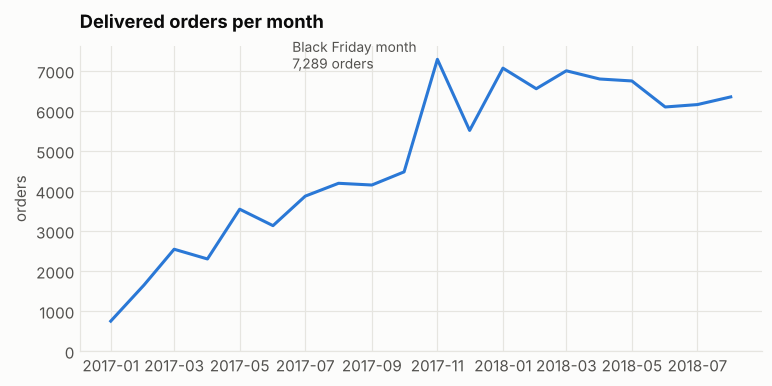

In [4]:
fig, ax = plt.subplots(figsize=(8, 3.6))
x = pd.to_datetime(monthly["month"])
ax.plot(x, monthly["orders"], color=COLORS["blue"])
ax.set_ylim(0, None)
ax.set_title("Delivered orders per month")
ax.set_ylabel("orders")

peak = monthly.loc[monthly["orders"].idxmax()]
ax.annotate(
    f"Black Friday month\n{peak['orders']:,.0f} orders",
    xy=(pd.to_datetime(peak["month"]), peak["orders"]),
    xytext=(-95, -6), textcoords="offset points", color=COLORS["muted"], fontsize=9,
)
save_figure(fig, "01_monthly_orders.png")
plt.show()

**What this shows.** Orders grew about sevenfold during 2017, spiked in November 2017 (Black Friday), and then levelled off at roughly 6,000 to 7,000 a month in 2018.

**Why it matters later.** The flat 2018 period is the cleanest stretch for measuring how much demand bounces around week to week, which is what the inventory notebook needs.

## Q2. Where are the customers?

In [5]:
demand = run_query("demand_by_state", con)
demand.head(10)

-- Q2. Where are the customers? Orders and freight burden by customer state.
-- The window function SUM(...) OVER () gives the national total on every row,
-- which lets us compute each state's share without a second query.
SELECT
    c.customer_state                                           AS state,
    COUNT(DISTINCT o.order_id)                                 AS orders,
    ROUND(100.0 * COUNT(DISTINCT o.order_id)
          / SUM(COUNT(DISTINCT o.order_id)) OVER (), 1)        AS pct_of_orders,
    ROUND(SUM(oi.price), 0)                                    AS revenue,
    ROUND(AVG(oi.freight_value), 2)                            AS avg_freight_per_item,
    ROUND(100.0 * SUM(oi.freight_value) / SUM(oi.price), 1)    AS freight_pct_of_price
FROM orders o
JOIN customers   c  ON c.customer_id = o.customer_id
JOIN order_items oi ON oi.order_id   = o.order_id
WHERE o.order_status = 'delivered'
  AND o.order_purchase_timestamp >= '2017-09-01'
  AND o.order_purchase_timestamp <  '2018-09-

,state,orders,pct_of_orders,revenue,avg_freight_per_item,freight_pct_of_price
0,SP,31828,42.9,3976325.0,15.15,13.9
1,RJ,9345,12.6,1323527.0,21.36,17.3
2,MG,8705,11.7,1216238.0,21.00,17.1
3,RS,3941,5.3,549134.0,22.07,18.3
4,PR,3710,5.0,505791.0,20.78,17.5
5,SC,2691,3.6,390198.0,22.12,17.6
6,BA,2482,3.3,369483.0,27.12,20.5
7,DF,1665,2.2,233355.0,21.41,17.1
8,ES,1516,2.0,209696.0,22.45,18.0
9,GO,1501,2.0,214307.0,22.85,18.5


**What this shows.** São Paulo state (SP) alone is 43% of orders. SP, Rio de Janeiro (RJ) and Minas Gerais (MG) together are two thirds. These three states sit next to each other in the Southeast.

Look at the last two columns. A customer in SP pays about R$15 freight per item, which is 14% of the product price. A customer in Bahia (BA) or Pernambuco (PE) in the Northeast pays R$27 to R$33, more than 20% of the price. Far-away customers pay a lot more for the same product.

## Q3. Is supply located where demand is?

In [6]:
balance = run_query("supply_vs_demand", con)
balance.head(10)

-- Q3. Is supply located where demand is? Share of items SOLD FROM each state
-- next to the share of items SHIPPED TO each state. Two CTEs, then a join.
WITH study_items AS (
    SELECT oi.seller_id, o.customer_id
    FROM order_items oi
    JOIN orders o ON o.order_id = oi.order_id
    WHERE o.order_status = 'delivered'
      AND o.order_purchase_timestamp >= '2017-09-01'
      AND o.order_purchase_timestamp <  '2018-09-01'
),
supply AS (
    SELECT s.seller_state AS state, COUNT(*) AS items_shipped_from
    FROM study_items si
    JOIN sellers s ON s.seller_id = si.seller_id
    GROUP BY s.seller_state
),
demand AS (
    SELECT c.customer_state AS state, COUNT(*) AS items_shipped_to
    FROM study_items si
    JOIN customers c ON c.customer_id = si.customer_id
    GROUP BY c.customer_state
)
SELECT
    d.state,
    ROUND(100.0 * COALESCE(s.items_shipped_from, 0)
          / (SELECT COUNT(*) FROM study_items), 1)   AS pct_of_supply,
    ROUND(100.0 * d.items_shipped_to
          / (S

,state,pct_of_supply,pct_of_demand
0,SP,71.9,43.1
1,RJ,4.6,12.6
2,MG,7.0,11.7
3,RS,1.9,5.4
4,PR,7.9,5.0
5,SC,3.3,3.7
6,BA,0.6,3.3
7,DF,0.8,2.2
8,ES,0.3,2.0
9,GO,0.5,2.0


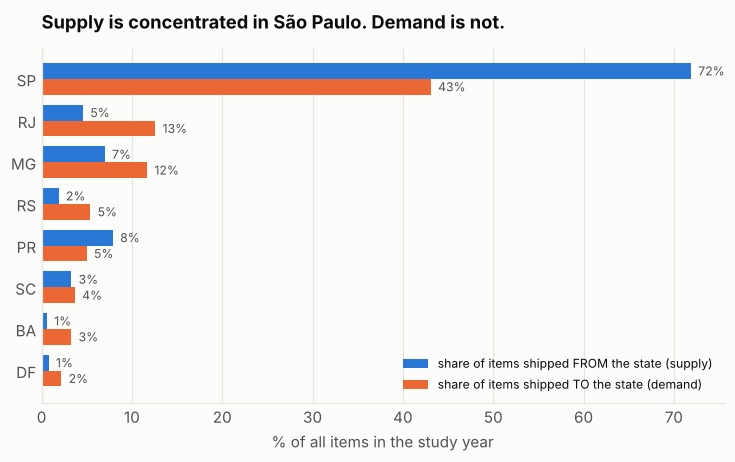

In [7]:
top = balance.head(8).iloc[::-1]          # reverse so the biggest state is at the top
fig, ax = plt.subplots(figsize=(8, 4.2))
y = range(len(top))
h = 0.38
ax.barh([i + h / 2 for i in y], top["pct_of_supply"], height=h, color=COLORS["blue"],
        label="share of items shipped FROM the state (supply)")
ax.barh([i - h / 2 for i in y], top["pct_of_demand"], height=h, color=COLORS["orange"],
        label="share of items shipped TO the state (demand)")
for i, (s, d) in enumerate(zip(top["pct_of_supply"], top["pct_of_demand"])):
    ax.text(s + 0.8, i + h / 2, f"{s:.0f}%", va="center", fontsize=8, color=COLORS["muted"])
    ax.text(d + 0.8, i - h / 2, f"{d:.0f}%", va="center", fontsize=8, color=COLORS["muted"])
ax.set_yticks(list(y))
ax.set_yticklabels(top["state"])
ax.set_xlabel("% of all items in the study year")
ax.set_title("Supply is concentrated in São Paulo. Demand is not.")
ax.grid(axis="y", visible=False)
ax.legend(loc="lower right", fontsize=8)
save_figure(fig, "01_supply_vs_demand.png")
plt.show()

**What this shows.** 72% of items ship out of São Paulo state, but only 43% of items are delivered there. Almost every other state receives more than it ships (Paraná, PR, is the one exception among the big ones). RJ takes 13% of the demand and supplies under 5% of it.

**This is the core problem of the project.** Because inventory sits with sellers in SP, more than half of all items have to travel a long way to reach the customer, one parcel at a time.

## Q4. How long do customers wait, and how often is an order late?

In [8]:
delivery = run_query("delivery_by_state", con)
delivery

-- Q4. How long do customers wait, and how often is the order late?
-- julianday() turns a timestamp into a day number, so subtracting two of them
-- gives elapsed days. "Late" means delivered after the date Olist promised.
SELECT
    c.customer_state                                             AS state,
    COUNT(*)                                                     AS orders,
    ROUND(AVG(julianday(o.order_delivered_customer_date)
            - julianday(o.order_purchase_timestamp)), 1)         AS avg_days_to_deliver,
    ROUND(AVG(julianday(o.order_estimated_delivery_date)
            - julianday(o.order_purchase_timestamp)), 1)         AS avg_days_promised,
    ROUND(100.0 * AVG(CASE
            WHEN o.order_delivered_customer_date > o.order_estimated_delivery_date
            THEN 1 ELSE 0 END), 1)                               AS pct_late
FROM orders o
JOIN customers c ON c.customer_id = o.customer_id
WHERE o.order_status = 'delivered'
  AND o.order_delivered_customer_date IS N

,state,orders,avg_days_to_deliver,avg_days_promised,pct_late
0,RR,28,28.7,47.9,14.3
1,AM,100,28.0,49.0,4.0
2,AP,52,25.8,48.6,0.0
3,PA,673,25.5,37.0,15.9
4,AL,283,23.7,31.6,23.0
5,MA,528,22.2,28.1,24.6
6,CE,952,21.8,29.8,18.6
7,AC,47,21.2,44.4,6.4
8,SE,230,20.3,28.8,18.3
9,PB,386,20.0,32.0,10.6


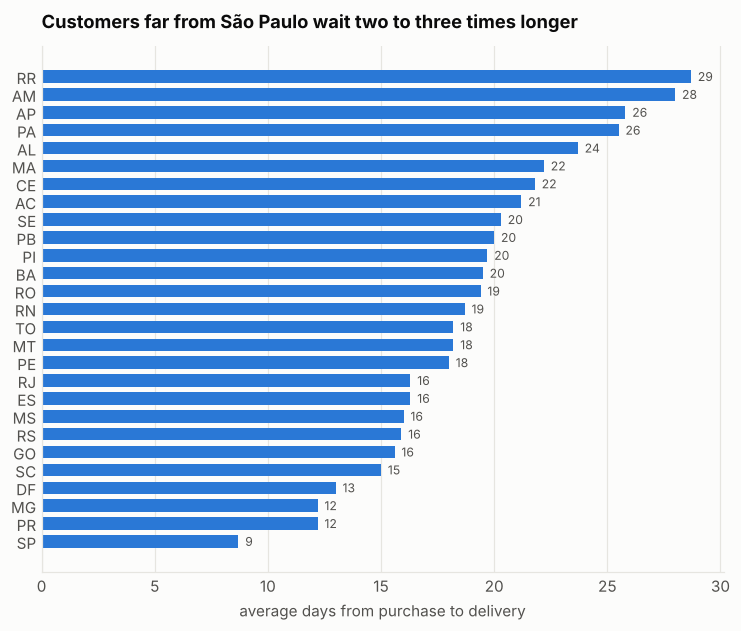

In [9]:
d = delivery.sort_values("avg_days_to_deliver")
fig, ax = plt.subplots(figsize=(8, 6.2))
ax.barh(d["state"], d["avg_days_to_deliver"], color=COLORS["blue"], height=0.7)
for state, days in zip(d["state"], d["avg_days_to_deliver"]):
    ax.text(days + 0.3, state, f"{days:.0f}", va="center", fontsize=8, color=COLORS["muted"])
ax.set_xlabel("average days from purchase to delivery")
ax.set_title("Customers far from São Paulo wait two to three times longer")
ax.grid(axis="y", visible=False)
save_figure(fig, "01_delivery_days_by_state.png")
plt.show()

**What this shows.** A customer in SP waits about 9 days on average. Customers in the North and Northeast wait 20 to 29 days. Those same regions also have the highest late rates.

## Q5. What does distance cost?

In [10]:
run_query("same_state_vs_cross_state", con)

-- Q5. What does distance cost? Compare items that stay inside one state with
-- items that cross a state line.
SELECT
    CASE WHEN s.seller_state = c.customer_state
         THEN 'same state' ELSE 'cross state' END                AS lane_type,
    COUNT(*)                                                     AS items,
    ROUND(AVG(oi.freight_value), 2)                              AS avg_freight,
    ROUND(AVG(julianday(o.order_delivered_customer_date)
            - julianday(o.order_delivered_carrier_date)), 1)     AS avg_transit_days,
    ROUND(100.0 * AVG(CASE
            WHEN o.order_delivered_customer_date > o.order_estimated_delivery_date
            THEN 1 ELSE 0 END), 1)                               AS pct_late
FROM order_items oi
JOIN orders    o ON o.order_id    = oi.order_id
JOIN customers c ON c.customer_id = o.customer_id
JOIN sellers   s ON s.seller_id   = oi.seller_id
WHERE o.order_status = 'delivered'
  AND o.order_delivered_customer_date IS NOT NULL
  AND o.order_de

,lane_type,items,avg_freight,avg_transit_days,pct_late
0,cross state,53394,24.14,12.1,10.6
1,same state,31535,13.43,4.6,6.5


**What this shows.** An item that crosses a state line costs about R$24 to ship and spends 12 days with the carrier. An item that stays inside one state costs about R$13 and spends under 5 days in transit. Crossing a state line nearly doubles the freight and more than doubles the transit time.

63% of items cross a state line.

## Q6. Which shipping lanes carry the most volume?

A lane is an origin and destination pair, here seller state to customer state.

In [11]:
run_query("top_lanes", con)

-- Q6. Which shipping lanes (seller state -> customer state) carry the most volume?
SELECT
    s.seller_state || ' -> ' || c.customer_state                 AS lane,
    COUNT(*)                                                     AS items,
    ROUND(AVG(oi.freight_value), 2)                              AS avg_freight,
    ROUND(AVG(julianday(o.order_delivered_customer_date)
            - julianday(o.order_delivered_carrier_date)), 1)     AS avg_transit_days
FROM order_items oi
JOIN orders    o ON o.order_id    = oi.order_id
JOIN customers c ON c.customer_id = o.customer_id
JOIN sellers   s ON s.seller_id   = oi.seller_id
WHERE o.order_status = 'delivered'
  AND o.order_delivered_customer_date IS NOT NULL
  AND o.order_delivered_carrier_date  IS NOT NULL
  AND o.order_purchase_timestamp >= '2017-09-01'
  AND o.order_purchase_timestamp <  '2018-09-01'
GROUP BY lane
ORDER BY items DESC
LIMIT 12;



,lane,items,avg_freight,avg_transit_days
0,SP -> SP,28108,13.14,4.6
1,SP -> RJ,7168,20.74,13.8
2,SP -> MG,6548,20.64,9.2
3,SP -> RS,3061,20.82,13.4
4,SP -> PR,2756,20.47,9.7
5,PR -> SP,2695,19.23,7.8
6,SP -> SC,2080,21.34,12.6
7,SP -> BA,2046,24.56,16.8
8,MG -> SP,2019,22.60,7.5
9,SP -> GO,1284,20.50,12.6


**What this shows.** Eight of the top ten lanes start in SP. The second biggest lane, SP to RJ, moves over 7,000 items a year one parcel at a time and takes about 14 days in transit, even though the two state capitals are only about 360 km apart.

## Q7. What sells the most, and what is expensive to ship?

In [12]:
categories = run_query("top_categories", con)
categories

-- Q7. What do we sell the most of, and which categories are expensive to ship?
-- RANK() OVER (...) numbers the categories from best seller down.
SELECT
    RANK() OVER (ORDER BY COUNT(*) DESC)                         AS rank_by_units,
    COALESCE(t.product_category_name_english,
             p.product_category_name, 'unknown')                 AS category,
    COUNT(*)                                                     AS units,
    ROUND(SUM(oi.price), 0)                                      AS revenue,
    ROUND(AVG(oi.price), 2)                                      AS avg_price,
    ROUND(AVG(p.product_weight_g) / 1000.0, 2)                   AS avg_weight_kg,
    ROUND(100.0 * SUM(oi.freight_value) / SUM(oi.price), 1)      AS freight_pct_of_price
FROM order_items oi
JOIN orders   o ON o.order_id   = oi.order_id
JOIN products p ON p.product_id = oi.product_id
LEFT JOIN category_translation t
       ON t.product_category_name = p.product_category_name
WHERE o.order_status = 'deliv

,rank_by_units,category,units,revenue,avg_price,avg_weight_kg,freight_pct_of_price
0,1,bed_bath_table,8387,768511.0,91.63,1.98,20.4
1,2,health_beauty,7600,986036.0,129.74,0.98,14.6
2,3,sports_leisure,6432,736116.0,114.45,1.60,16.8
3,4,computers_accessories,5974,673424.0,112.73,0.93,17.0
4,5,furniture_decor,5914,535379.0,90.53,2.69,23.3
5,6,housewares,5147,486807.0,94.58,3.41,23.2
6,7,watches_gifts,5016,962328.0,191.85,0.56,8.8
7,8,auto,3358,452591.0,134.78,2.40,16.1
8,9,telephony,3341,252159.0,75.47,0.28,20.8
9,10,garden_tools,3221,331084.0,102.79,2.68,22.4


**What this shows.** Bed, bath and table is the top category by units. Health and beauty is the top by revenue. The last column shows where freight hurts the most: for furniture, housewares and garden tools, freight is 22% to 23% of the product price, because the items are heavy and cheap. For watches it is under 9%.

## Q8. Does slow delivery hurt customer satisfaction?

In [13]:
reviews = run_query("late_delivery_vs_reviews", con)
reviews

-- Q8. Does slow delivery hurt customer satisfaction? Review score by how the
-- delivery went. An order can have more than one review, so the CTE averages
-- them to one score per order first.
WITH order_score AS (
    SELECT order_id, AVG(review_score) AS score
    FROM reviews
    GROUP BY order_id
)
SELECT
    CASE
        WHEN o.order_delivered_customer_date <= o.order_estimated_delivery_date
             AND julianday(o.order_delivered_customer_date)
               - julianday(o.order_purchase_timestamp) <= 7  THEN '1. on time, within a week'
        WHEN o.order_delivered_customer_date <= o.order_estimated_delivery_date
                                                             THEN '2. on time, over a week'
        ELSE                                                      '3. late'
    END                                                          AS delivery_outcome,
    COUNT(*)                                                     AS orders,
    ROUND(AVG(r.score), 2)         

,delivery_outcome,orders,avg_review_score,pct_bad_reviews
0,"1. on time, within a week",20505,4.42,7.5
1,"2. on time, over a week",46451,4.24,10.0
2,3. late,6768,2.55,54.4


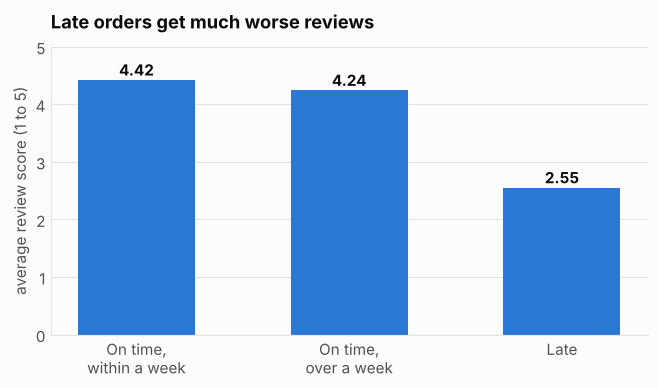

In [14]:
fig, ax = plt.subplots(figsize=(7, 3.4))
labels = ["On time,\nwithin a week", "On time,\nover a week", "Late"]
bars = ax.bar(labels, reviews["avg_review_score"], color=COLORS["blue"], width=0.55)
for bar, score in zip(bars, reviews["avg_review_score"]):
    ax.text(bar.get_x() + bar.get_width() / 2, score + 0.08, f"{score:.2f}",
            ha="center", fontsize=10, fontweight="bold")
ax.set_ylim(0, 5)
ax.set_ylabel("average review score (1 to 5)")
ax.set_title("Late orders get much worse reviews")
ax.grid(axis="x", visible=False)
save_figure(fig, "01_reviews_by_delivery.png")
plt.show()

**What this shows.** Orders that arrive on time within a week average 4.4 stars. Late orders average 2.6 stars, and more than half of them get a 1 or 2 star review. Delivery speed is not only a cost issue. It drives how customers rate the whole purchase.

## What we learned

| Finding | Number |
|---|---|
| Supply is concentrated in one state | 72% of items ship from SP, 43% are delivered there |
| Most items travel far | 63% of items cross a state line |
| Distance is expensive | R\$24 freight across states vs R\$13 within a state |
| Distance is slow | 12 days in transit across states vs under 5 within |
| Slow delivery costs satisfaction | 2.6 stars when late vs 4.4 when fast |

**The question for the rest of the project:** what if Olist held inventory in a few regional fulfillment centers, close to customers, instead of leaving all of it with sellers? Stock would travel to each center in bulk by truck, which is cheap per item, and the last leg to the customer would be short.

- **Notebook 2** decides where those fulfillment centers should go and what they save.
- **Notebook 3** decides how much stock each one needs to hold.

In [15]:
con.close()